# Visualize the migrated final objects (new vocabulary)

Reads the **staged migrated** `final_{sp}_migrated.h5ad` objects (the new `cell_type`/`cell_subtype`
vocabulary), and renders UMAP + composition + a marker sanity dotplot, using `uns["display_names"]`
for pretty labels. Any scanpy env works (`rsc_uv` fine). Set `SPECIES` and re-run.

**Which objects:** the staged migrated set (new vocab), NOT the live Jul-29 objects (old vocab).
If you've already promoted, point PATH at the live `final_{sp}.h5ad` instead.

## Load

In [15]:
%matplotlib inline
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt, scanpy as sc

SPECIES = "mouse"     # "human" | "mouse"
RUN = "xmens_annotation_v1_20260810"
PATH = f"data/interim/migrated/{RUN}/final_{SPECIES}_migrated.h5ad"
# after promotion, instead: PATH = f"data/interim/final_{SPECIES}.h5ad"

a = ad.read_h5ad(PATH)
disp = a.uns.get("display_names", {})
dt = disp.get("cell_type", {}) if isinstance(disp, dict) else {}
ds = disp.get("cell_subtype", {}) if isinstance(disp, dict) else {}
print(a.shape)
print("cell_type:", sorted(a.obs["cell_type"].astype(str).unique()))
print("has display_names:", bool(dt))
# map to display labels for plotting (fall back to raw if missing)
a.obs["ct_disp"] = a.obs["cell_type"].astype(str).map(lambda x: dt.get(x, x))
a.obs["cst_disp"] = a.obs["cell_subtype"].astype(str).map(lambda x: ds.get(x, x) if x else "(none)")

(57033, 33698)
cell_type: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_cell', 'epithelial_cell', 'immune_cell', 'mesothelial_cell', 'smooth_muscle_cell']
has display_names: True


## 1. Coarse cell_type on UMAP

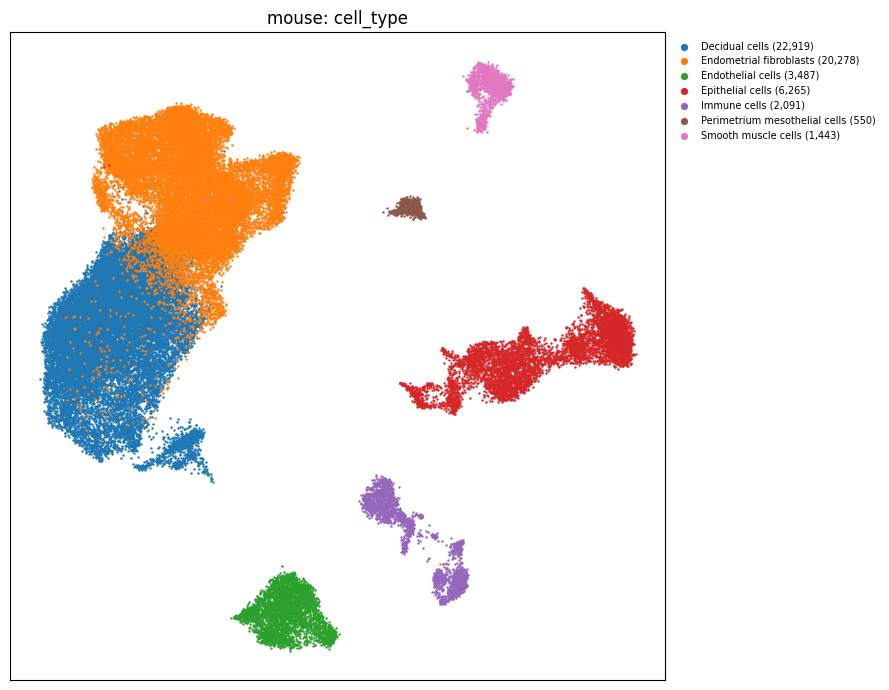

In [16]:
umap_key = "X_umap_scVI" if "X_umap_scVI" in a.obsm else ("X_umap_migrated" if "X_umap_migrated" in a.obsm else None)
assert umap_key, f"no UMAP in obsm: {list(a.obsm)}"
U = np.asarray(a.obsm[umap_key])
cats = a.obs["ct_disp"].astype("category")
cmap = plt.get_cmap("tab10" if cats.cat.categories.size<=10 else "tab20")
fig, ax = plt.subplots(figsize=(9,7))
for i,c in enumerate(cats.cat.categories):
    m = (a.obs["ct_disp"]==c).values
    ax.scatter(U[m,0], U[m,1], s=3, color=cmap(i%cmap.N), label=f"{c} ({int(m.sum()):,})", linewidths=0)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{SPECIES}: cell_type")
ax.legend(markerscale=3, fontsize=7, frameon=False, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

## 2. Fine cell_subtype on UMAP (cells with a subtype)

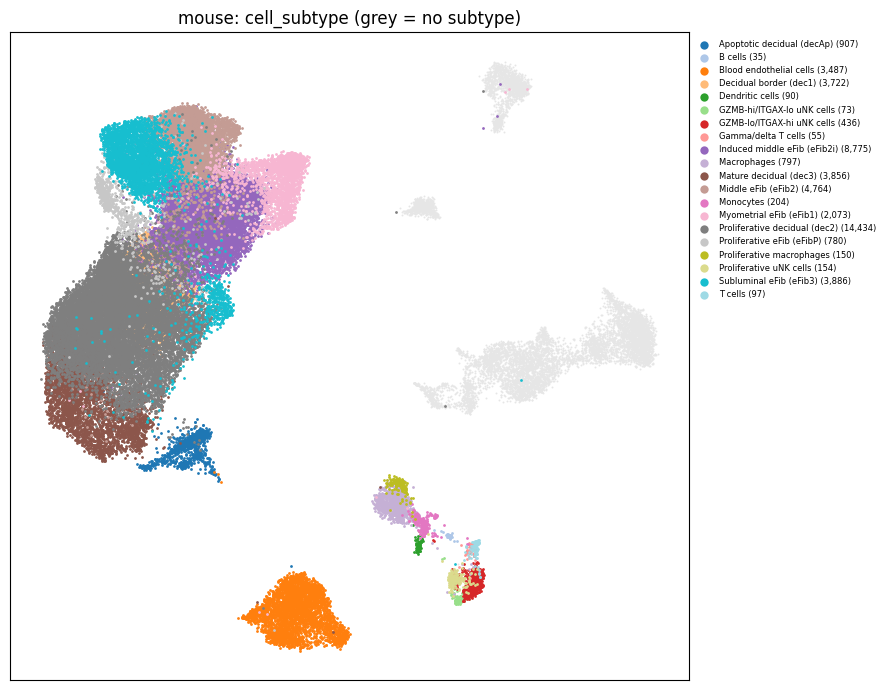

In [17]:
has_sub = (a.obs["cell_subtype"].astype(str).str.len()>0).values
sub = a.obs.loc[has_sub, "cst_disp"].astype("category")
cmapS = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(9,7))
ax.scatter(U[~has_sub,0], U[~has_sub,1], s=2, color="0.9", linewidths=0)  # no-subtype greyed
for i,c in enumerate(sorted(sub.cat.categories)):
    m = has_sub & (a.obs["cst_disp"]==c).values
    ax.scatter(U[m,0], U[m,1], s=4, color=cmapS(i%cmapS.N), label=f"{c} ({int(m.sum()):,})", linewidths=0)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{SPECIES}: cell_subtype (grey = no subtype)")
ax.legend(markerscale=3, fontsize=6, frameon=False, ncol=1, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

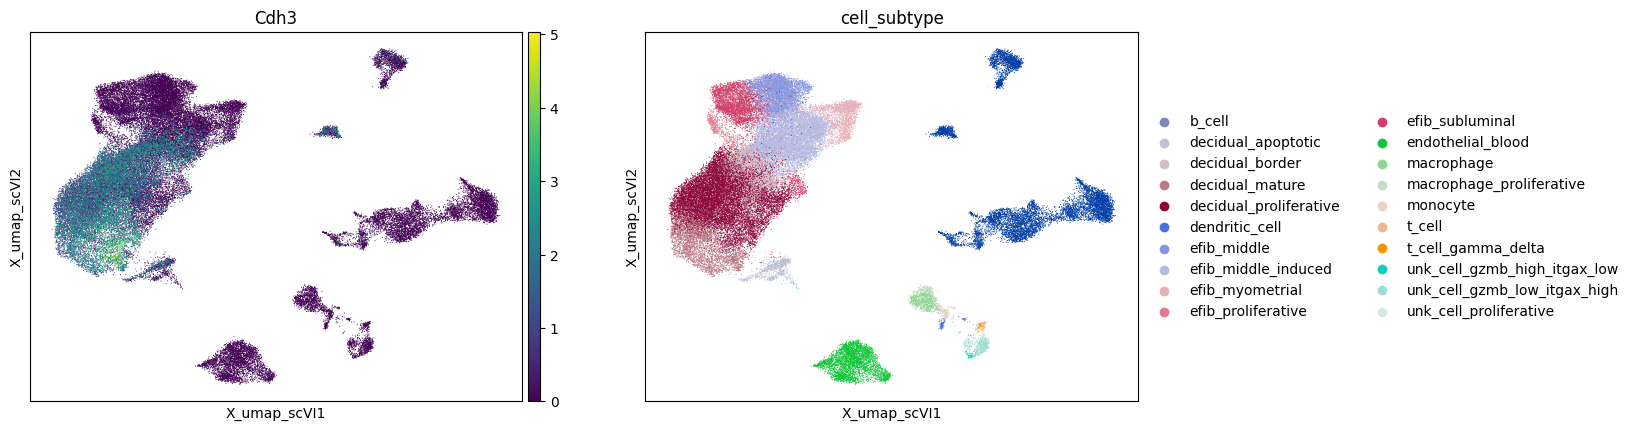

In [21]:
sc.pl.embedding(a, color = ['Cdh3', 'cell_subtype'], basis  = 'X_umap_scVI')

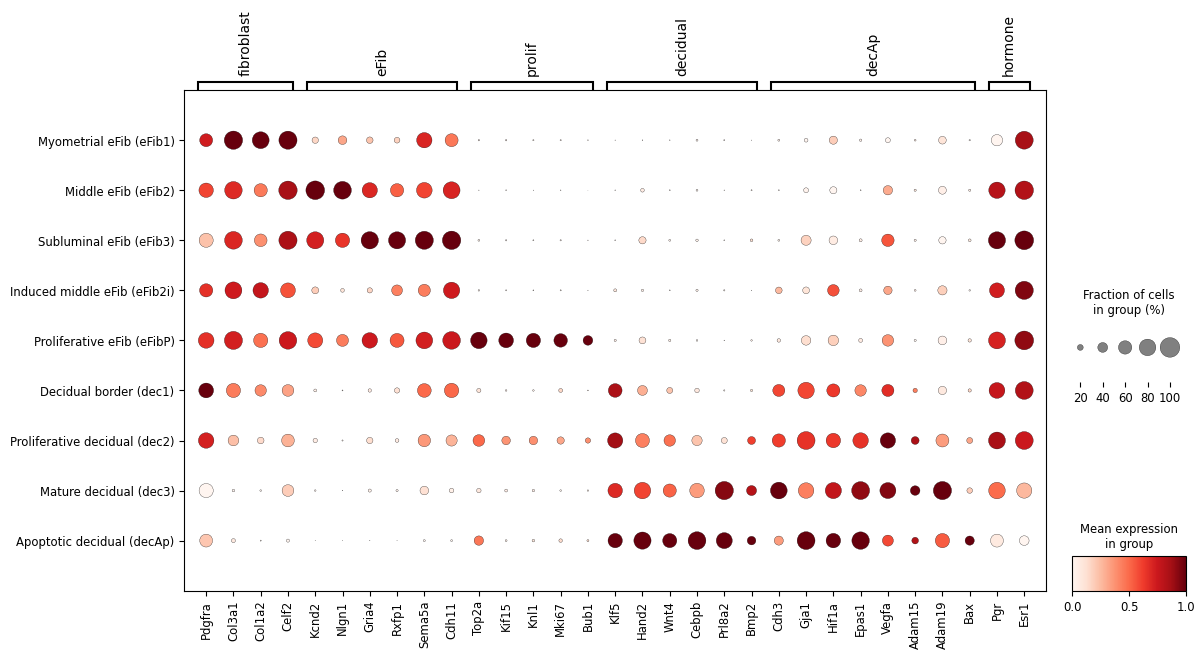

In [22]:
## Stromal marker dotplot (manuscript panel) — the biological confirmation of the subtypes
# Same panel as the 04c stromal reannotation notebook, grouped along the subtype diagonal.
# This is embedding-independent: it shows each subtype expresses its defining program,
# regardless of how the cells scatter on any UMAP. Run with SPECIES = "mouse".

MARKERS_MOUSE = {
    "fibroblast": ["Pdgfra", "Col3a1", "Col1a2", "Celf2"],
    "eFib":       ["Kcnd2", "Nlgn1", "Gria4", "Rxfp1", "Sema5a", "Cdh11"],
    "prolif":     ["Top2a", "Kif15", "Knl1", "Mki67", "Bub1"],
    "decidual":   ["Klf5", "Hand2", "Wnt4", "Cebpb", "Prl8a2", "Bmp2"],
    "decAp":      ["Cdh3", "Gja1", "Hif1a", "Epas1", "Vegfa", "Adam15", "Adam19", "Bax"],
    "hormone":    ["Pgr", "Esr1"],
}
STROMAL_ORDER = [
    "efib_myometrial", "efib_middle", "efib_subluminal", "efib_middle_induced", "efib_proliferative",
    "decidual_border", "decidual_proliferative", "decidual_mature", "decidual_apoptotic",
]

strom = a[a.obs["cell_subtype"].astype(str).isin(STROMAL_ORDER)].copy()
present_order = [s for s in STROMAL_ORDER if s in set(strom.obs["cell_subtype"].astype(str))]

plot_sets = {k: [g for g in v if g in strom.var_names] for k, v in MARKERS_MOUSE.items()}
plot_sets = {k: v for k, v in plot_sets.items() if v}
missing = [g for v in MARKERS_MOUSE.values() for g in v if g not in strom.var_names]
if missing:
    print("WARNING genes not in var_names (dropped):", missing)

# y-axis in display names with legacy code, matching your figures
ds = (a.uns.get("display_names", {}) or {}).get("cell_subtype", {})
strom.obs["subtype_disp"] = strom.obs["cell_subtype"].astype(str).map(lambda x: ds.get(x, x))
order_disp = [ds.get(s, s) for s in present_order]
strom.obs["subtype_disp"] = strom.obs["subtype_disp"].astype("category").cat.set_categories(order_disp)

sc.pl.dotplot(
    strom, plot_sets, groupby="subtype_disp", categories_order=order_disp,
    standard_scale="var", cmap="Reds",
    figsize=(0.32 * sum(len(v) for v in plot_sets.values()) + 3, 0.5 * len(present_order) + 2),
    show=True,
)

candidate reference objects found:
/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission/20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
ref label column: cell_subtype_annotations | sample values: ['dec1', 'dec2', 'dec3', 'decAp', 'eFib1', 'eFib2', 'eFib2i', 'eFib3', 'eFibP']

joined 19854/20278 new fibroblast cells to a deposited label (97.9%)
fibroblast-subtype agreement (new vs deposited): 85.0% on 19854 cells

confusion (rows=deposited old, cols=new cell_subtype):
cell_subtype            efib_middle  efib_middle_induced  efib_myometrial  \
old_norm                                                                    
decidual_apoptotic                0                    1                0   
decidual_border                  43                  580                1   
decidual_mature                  14                    7                1   
decidual_proliferative           20                  135                5   
efib_middle                    4259   

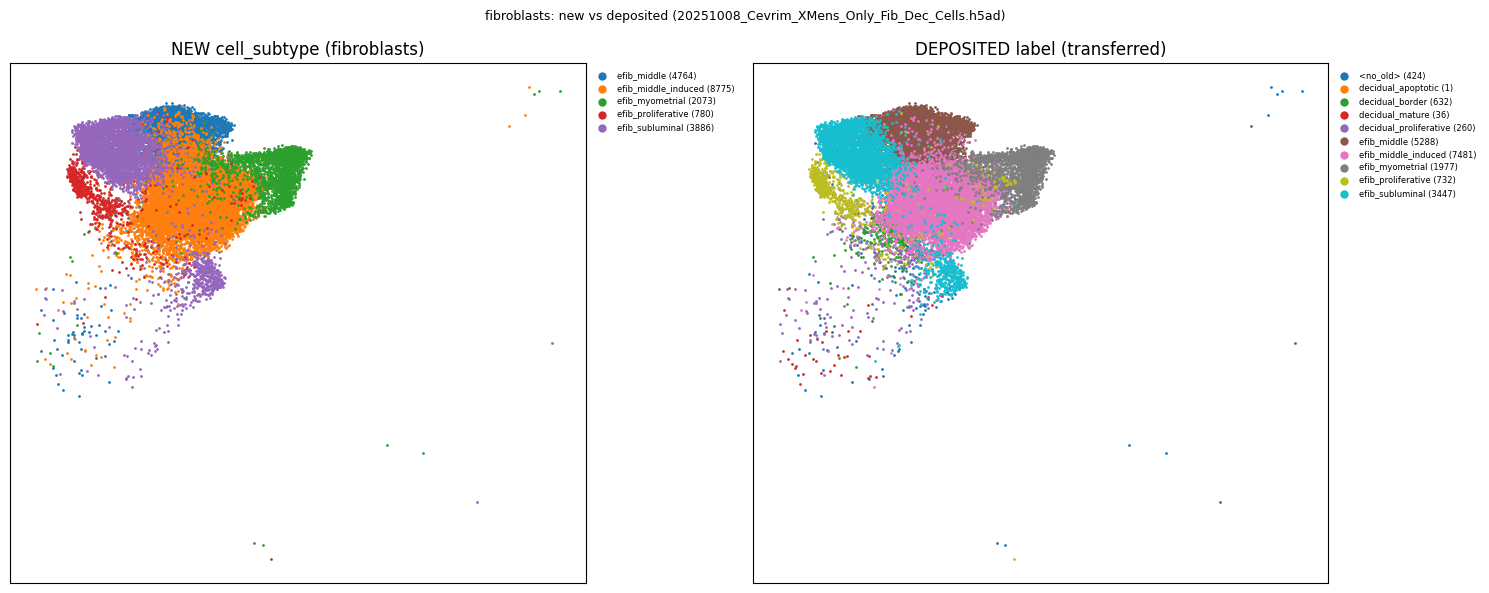

In [31]:
## Compare CURRENT fibroblast subtypes vs the deposited Cevrim XMens_Only_Fib_Dec labels
## (loads the old deposited object, transfers its labels by canonical barcode key, plots on new UMAP)
import anndata as ad, pandas as pd, numpy as np, re, os, glob
import matplotlib.pyplot as plt

# --- path to the deposited reference (adjust if the filename/date differs) ---
REF_DIR = "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission"
cand = sorted(glob.glob(f"{REF_DIR}/*Fib_Dec*Cells*.h5ad")) or sorted(glob.glob(f"{REF_DIR}/*Fib_Dec*.h5ad"))
print("candidate reference objects found:")

REF = f"{REF_DIR}/20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
print(REF)

ref = ad.read_h5ad(REF, backed="r").obs.copy()
label_col = next((c for c in ["cell_subtype_annotations","cell_subtype","subtype","fine_refined"]
                  if c in ref.columns), None)
assert label_col, f"no label column found in ref; columns = {list(ref.columns)[:40]}"
print(f"ref label column: {label_col} | sample values: {sorted(set(ref[label_col].astype(str)))[:14]}")

def _canon(s):
    s = s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return s.str.replace("bleeding", "menstrual", regex=False)
def _key(o):
    bc = o["cell_barcode"] if "cell_barcode" in o else pd.Series(o.index, index=o.index)
    return _canon(o["sample"]) + "||" + bc.astype(str).str.replace(r"-\d+$", "", regex=True)

assert "sample" in ref.columns, f"ref has no 'sample' col; has {list(ref.columns)[:40]}"
ref["k"] = _key(ref)

new_fib = a[a.obs["cell_type"].astype(str) == "endometrial_fibroblast"].copy()
assert "sample" in new_fib.obs, f"new obj has no 'sample'; has {list(new_fib.obs.columns)[:40]}"
new_fib.obs["k"] = _key(new_fib.obs)

old_map = ref.drop_duplicates("k").set_index("k")[label_col].astype(str)
new_fib.obs["old_label"] = new_fib.obs["k"].map(old_map).fillna("<no_old>")
NAMEMAP = {"eFib1":"efib_myometrial","eFib2":"efib_middle","eFib2i":"efib_middle_induced",
           "eFib3":"efib_subluminal","eFibP":"efib_proliferative",
           "dec1":"decidual_border","dec2":"decidual_proliferative","dec3":"decidual_mature","decAp":"decidual_apoptotic"}
new_fib.obs["old_norm"] = new_fib.obs["old_label"].map(lambda x: NAMEMAP.get(x, x))

joined = (new_fib.obs["old_label"] != "<no_old>")
print(f"\njoined {int(joined.sum())}/{new_fib.n_obs} new fibroblast cells to a deposited label "
      f"({100*joined.mean():.1f}%)")

both = joined & new_fib.obs["cell_subtype"].astype(str).str.startswith("efib")
if int(both.sum()):
    agree = (new_fib.obs.loc[both,"old_norm"] == new_fib.obs.loc[both,"cell_subtype"].astype(str))
    print(f"fibroblast-subtype agreement (new vs deposited): {100*agree.mean():.1f}% on {int(both.sum())} cells")
    print("\nconfusion (rows=deposited old, cols=new cell_subtype):")
    print(pd.crosstab(new_fib.obs.loc[both,"old_norm"], new_fib.obs.loc[both,"cell_subtype"].astype(str)))

uk = "X_umap_scVI" if "X_umap_scVI" in new_fib.obsm else [k for k in new_fib.obsm if "umap" in k.lower()][0]
U = np.asarray(new_fib.obsm[uk])
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for axi, colr, title in [(0,"cell_subtype","NEW cell_subtype (fibroblasts)"),
                         (1,"old_norm","DEPOSITED label (transferred)")]:
    cats = sorted(new_fib.obs[colr].astype(str).unique())
    cmap = plt.get_cmap("tab10" if len(cats)<=10 else "tab20")
    for i,c in enumerate(cats):
        m = (new_fib.obs[colr].astype(str)==c).values
        ax[axi].scatter(U[m,0],U[m,1],s=4,color=cmap(i%cmap.N),label=f"{c} ({int(m.sum())})",linewidths=0)
    ax[axi].set_title(title); ax[axi].set_xticks([]); ax[axi].set_yticks([])
    ax[axi].legend(markerscale=3,fontsize=6,frameon=False,bbox_to_anchor=(1,1))
plt.suptitle(f"fibroblasts: new vs deposited ({REF.split('/')[-1]})", fontsize=9)
plt.tight_layout(); plt.show()

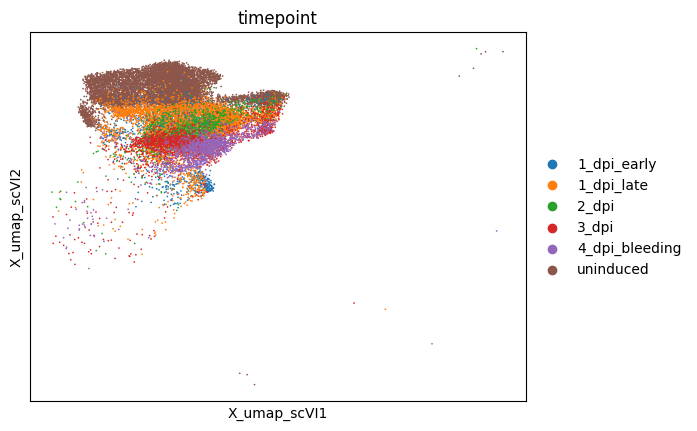

In [33]:
sc.pl.embedding(new_fib, color = 'timepoint', basis = 'X_umap_scVI')

In [34]:
import anndata as ad
for sp, path in [("human","data/interim/migrated/xmens_annotation_v1_20260810/final_human_migrated.h5ad"),
                 ("mouse","data/interim/migrated/xmens_annotation_v1_20260810/final_mouse_migrated.h5ad")]:
    a = ad.read_h5ad(path)
    empty = a.obs["cell_subtype"].astype(str) == ""
    n = int(empty.sum())
    a.obs["cell_subtype"] = a.obs["cell_subtype"].astype(str)
    a.obs.loc[empty, "cell_subtype"] = a.obs.loc[empty, "cell_type"].astype(str)
    # mirror coarse display names into the subtype display dict for the filled types
    dn = a.uns.get("display_names", {})
    if isinstance(dn, dict):
        ct_disp = dn.get("cell_type", {})
        cst_disp = dict(dn.get("cell_subtype", {}))
        for ct in a.obs.loc[empty, "cell_type"].astype(str).unique():
            cst_disp.setdefault(ct, ct_disp.get(ct, ct))
        dn["cell_subtype"] = cst_disp
        a.uns["display_names"] = dn
    assert (a.obs["cell_subtype"].astype(str) == "").sum() == 0, "still empty!"
    a.write_h5ad(path)
    print(f"{sp}: filled {n} empty subtypes; cell_subtype now: {sorted(a.obs['cell_subtype'].astype(str).unique())}")

human: filled 60696 empty subtypes; cell_subtype now: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_blood', 'endothelial_lymph', 'epithelial_cell', 'epithelial_ciliated', 'macrophage', 'mast_cell', 'perivascular_cell', 'smooth_muscle_cell', 't_cell_cd4', 't_cell_cd8', 't_cell_gamma_delta', 't_cell_regulatory', 'unk_cell_gzmb_high_itgax_high', 'unk_cell_gzmb_low_itgax_low']
mouse: filled 8258 empty subtypes; cell_subtype now: ['b_cell', 'decidual_apoptotic', 'decidual_border', 'decidual_mature', 'decidual_proliferative', 'dendritic_cell', 'efib_middle', 'efib_middle_induced', 'efib_myometrial', 'efib_proliferative', 'efib_subluminal', 'endothelial_blood', 'epithelial_cell', 'macrophage', 'macrophage_proliferative', 'mesothelial_cell', 'monocyte', 'smooth_muscle_cell', 't_cell', 't_cell_gamma_delta', 'unk_cell_gzmb_high_itgax_low', 'unk_cell_gzmb_low_itgax_high', 'unk_cell_proliferative']


## 3. Composition

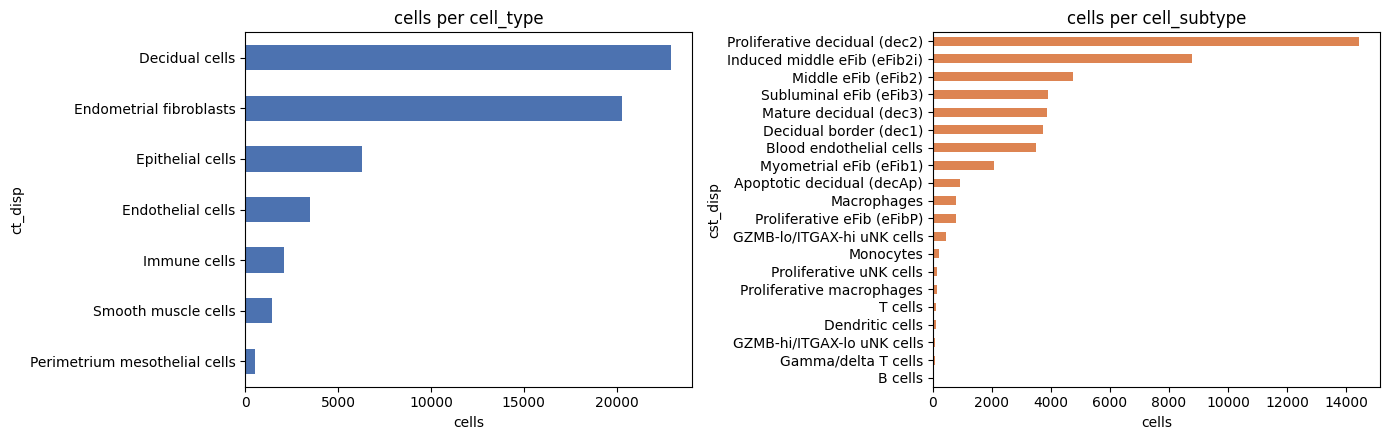

ct_disp                        cst_disp                     
Decidual cells                 Proliferative decidual (dec2)    14434
                               Mature decidual (dec3)            3856
                               Decidual border (dec1)            3722
                               Apoptotic decidual (decAp)         907
Endometrial fibroblasts        Induced middle eFib (eFib2i)      8775
                               Middle eFib (eFib2)               4764
                               Subluminal eFib (eFib3)           3886
                               Myometrial eFib (eFib1)           2073
                               Proliferative eFib (eFibP)         780
Endothelial cells              Blood endothelial cells           3487
Epithelial cells               (none)                            6265
Immune cells                   Macrophages                        797
                               GZMB-lo/ITGAX-hi uNK cells         436
                             

In [6]:
fig, ax = plt.subplots(1,2, figsize=(14,4.5))
a.obs["ct_disp"].value_counts().sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("cells per cell_type"); ax[0].set_xlabel("cells")
sc_counts = a.obs.loc[has_sub, "cst_disp"].value_counts().sort_values()
sc_counts.plot.barh(ax=ax[1], color="#DD8452")
ax[1].set_title("cells per cell_subtype"); ax[1].set_xlabel("cells")
plt.tight_layout(); plt.show()
print(a.obs.groupby("ct_disp")["cst_disp"].value_counts())

## 4. Marker sanity dotplot (coarse)
A quick "do the labels make sense" check — canonical markers per coarse type. Adjust the gene list to
your species' symbol casing (human UPPER, mouse Title). Uses `.X` (log-normalized) for the dotplot.

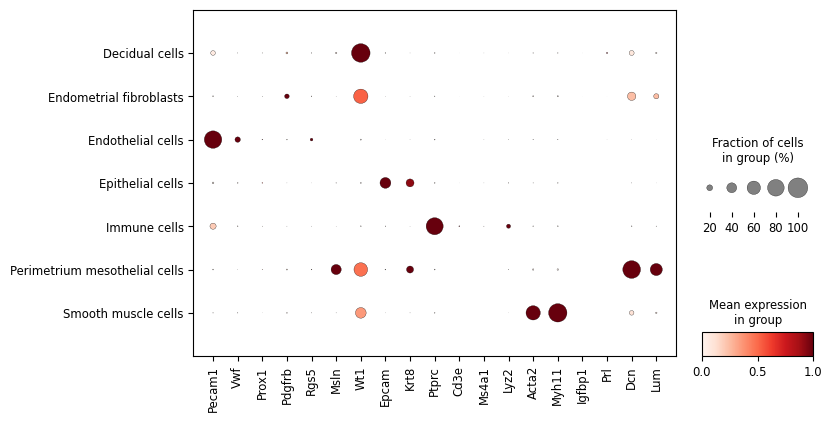

In [7]:
# canonical coarse markers — EDIT casing per species (human shown; for mouse use Title case)
MARKERS = {
 "human": ["PECAM1","VWF","PROX1","PDGFRB","RGS5","MSLN","WT1","EPCAM","KRT8",
           "PTPRC","CD3E","MS4A1","LYZ","ACTA2","MYH11","IGFBP1","PRL","DCN","LUM"],
 "mouse": ["Pecam1","Vwf","Prox1","Pdgfrb","Rgs5","Msln","Wt1","Epcam","Krt8",
           "Ptprc","Cd3e","Ms4a1","Lyz2","Acta2","Myh11","Igfbp1","Prl","Dcn","Lum"],
}[SPECIES]
present = [g for g in MARKERS if g in a.var_names]
missing = [g for g in MARKERS if g not in a.var_names]
if missing: print("absent from var_names (skipped):", missing)
sc.pl.dotplot(a, var_names=present, groupby="ct_disp", standard_scale="var",
              figsize=(max(8,0.4*len(present)), 0.5*a.obs["ct_disp"].nunique()+1))

## 5. (optional) Spatial — coarse type on tissue, per sample
Only if `obsm['spatial']` exists. Facets by sample if a sample column is present.

In [ ]:
if "spatial" in a.obsm:
    XY = np.asarray(a.obsm["spatial"])
    scol = next((c for c in ["sample","sample_id","library","batch"] if c in a.obs), None)
    samples = a.obs[scol].astype(str).unique() if scol else ["(all)"]
    samples = list(samples)[:6]
    fig, ax = plt.subplots(1, len(samples), figsize=(5*len(samples), 5), squeeze=False)
    cats = a.obs["ct_disp"].astype("category").cat.categories
    cmap = plt.get_cmap("tab10" if len(cats)<=10 else "tab20")
    col = {c:cmap(i%cmap.N) for i,c in enumerate(cats)}
    for j,s in enumerate(samples):
        m = (a.obs[scol].astype(str)==s).values if scol else np.ones(a.n_obs,bool)
        m &= np.isfinite(XY[:,0])
        for c in cats:
            mm = m & (a.obs["ct_disp"]==c).values
            if mm.sum(): ax[0,j].scatter(XY[mm,0], XY[mm,1], s=4, color=col[c], linewidths=0)
        ax[0,j].set_title(s, fontsize=8); ax[0,j].set_aspect("equal"); ax[0,j].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("no obsm['spatial'] on this object — skipping spatial panel")

In [8]:
print("STORED cell_type:", sorted(a.obs["cell_type"].astype(str).unique()))
print("STORED cell_subtype:", sorted(a.obs["cell_subtype"].astype(str).unique()))

STORED cell_type: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_cell', 'epithelial_cell', 'immune_cell', 'mesothelial_cell', 'smooth_muscle_cell']
STORED cell_subtype: ['', 'b_cell', 'decidual_apoptotic', 'decidual_border', 'decidual_mature', 'decidual_proliferative', 'dendritic_cell', 'efib_middle', 'efib_middle_induced', 'efib_myometrial', 'efib_proliferative', 'efib_subluminal', 'endothelial_blood', 'macrophage', 'macrophage_proliferative', 'monocyte', 't_cell', 't_cell_gamma_delta', 'unk_cell_gzmb_high_itgax_low', 'unk_cell_gzmb_low_itgax_high', 'unk_cell_proliferative']


In [9]:
# 1. Did eFib3's cell COUNT change? (re-annotation would change it; re-embedding wouldn't)
print("efib_subluminal count:", (a.obs["cell_subtype"]=="efib_subluminal").sum())
# expect 3886 — if so, same cells labeled, NOT reassigned

# 2. Is this a NEW embedding? check which UMAP you're plotting
print("obsm keys:", list(a.obsm))   # X_umap vs X_umap_migrated etc.

# 3. THE definitive test: are these the SAME barcodes as your old eFib3?
#    load your OLD final object and compare the barcode sets
import anndata as ad
old = ad.read_h5ad("data/interim/final_human.h5ad", backed="r")  # the Jul-29 original
new_e3 = set(a.obs_names[a.obs["cell_subtype"]=="efib_subluminal"])
# old object used fine_refined with value "eFib3"
old_e3 = set(old.obs_names[old.obs["fine_refined"].astype(str)=="eFib3"])
print("old eFib3:", len(old_e3), "| new efib_subluminal:", len(new_e3))
print("identical cell set:", old_e3 == new_e3)
print("overlap:", len(old_e3 & new_e3), "| only-old:", len(old_e3-new_e3), "| only-new:", len(new_e3-old_e3))

efib_subluminal count: 3886
obsm keys: ['X_scVI', 'X_umap_scVI', 'spatial']
old eFib3: 0 | new efib_subluminal: 3886
identical cell set: False
overlap: 0 | only-old: 0 | only-new: 3886


In [12]:
import anndata as ad
old = ad.read_h5ad("data/interim/final_mouse.h5ad", backed="r")
print("old obs columns:", [c for c in old.obs.columns if 'fib' in c.lower() or 'coarse' in c.lower() or 'fine' in c.lower() or 'subtype' in c.lower() or 'cell_type' in c.lower()])
# what labels does the old object actually have?
for col in old.obs.columns:
    vals = old.obs[col].astype(str).unique()
    if any('fib' in str(v).lower() or 'eFib' in str(v) for v in vals):
        print(f"  {col}: {sorted(vals)[:15]}")

old obs columns: ['coarse_refined', 'fine_refined']
  coarse_refined: ['decidual cells', 'endometrial fibroblasts', 'epithelial cells', 'immune cells', 'perimetrium cells', 'smooth muscle cells', 'vascular cells']
  fine_refined: ['', 'B Cells', 'DCs', 'Gamma/Delta T Cells', 'Gzmb hi. Itgax lo. uNK Cells', 'Gzmb lo. Itgax hi. uNK cells', 'Macrophages', 'Monocytes', 'Prolif. Macrophages', 'Prolif. uNK Cells', 'T Cells', 'dec1', 'dec2', 'dec3', 'decAp']


In [13]:
old.obs['fine_refined'].unique().tolist()

['eFibP',
 'eFib3',
 'eFib2',
 'eFib1',
 'eFib2i',
 'dec2',
 'dec1',
 'dec3',
 'decAp',
 '',
 'Macrophages',
 'Prolif. uNK Cells',
 'DCs',
 'Gamma/Delta T Cells',
 'Monocytes',
 'Gzmb hi. Itgax lo. uNK Cells',
 'Gzmb lo. Itgax hi. uNK cells',
 'T Cells',
 'Prolif. Macrophages',
 'B Cells']